In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns


In [16]:
MODEL_LABELS = {
    "mistral-small-2506": "Mistral-S",
    "mistral-large-2512": "Mistral-L",
    "gpt-5-mini": "GPT-5-mini",
    "gpt-5": "GPT-5",
    "llama-3.3-70b-versatile": "Llama-3.3-70B",
}

PROMPT_LABELS = {
    "zero_shot": "Zero-Shot",
    "zero_shot_with_table": "Zero-Shot + Table",
    "with_examples": "With Examples",
    "with_examples_and_table": "With Examples + Table",
}

# ColorBrewer Dark2 — perceptually distinct, print-friendly
_cb = sns.color_palette("Set2", len(PROMPT_LABELS))
PROMPT_COLORS = {label: _cb[i] for i, label in enumerate(PROMPT_LABELS.values())}

# Manual dataset order for the paper
DATASET_ORDER = [
    "hospital",
    "restaurant",
    "sisu",
    "tax"        
]

# Pretty dataset names for titles
DATASET_LABELS = {
    "restaurant": "Restaurant",
    "hospital": "Hospital",
    "tax": "Tax",
    "sisu": "SISU",
}


In [17]:
def apply_pretty_labels(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["model_label"] = df["model"].map(MODEL_LABELS).fillna(df["model"])
    df["prompt_label"] = df["prompt_key"].map(PROMPT_LABELS).fillna(df["prompt_key"])
    df["dataset_label"] = df["dataset"].map(DATASET_LABELS).fillna(df["dataset"])
    return df


def pareto_frontier(points: pd.DataFrame) -> pd.DataFrame:
    """
    True Pareto frontier for maximizing both recall and f1_score.
    A point is kept if it is not dominated by any other point.
    """
    if points.empty:
        return points.copy()

    pts = points.reset_index(drop=True).copy()
    keep = []

    for i, row_i in pts.iterrows():
        dominated = False
        for j, row_j in pts.iterrows():
            if i == j:
                continue

            no_worse = (
                row_j["recall"] >= row_i["recall"]
                and row_j["f1_score"] >= row_i["f1_score"]
            )
            strictly_better = (
                row_j["recall"] > row_i["recall"]
                or row_j["f1_score"] > row_i["f1_score"]
            )

            if no_worse and strictly_better:
                dominated = True
                break

        if not dominated:
            keep.append(i)

    frontier = pts.loc[keep].copy()
    frontier = frontier.sort_values(["recall", "f1_score"]).reset_index(drop=True)

    # Optional: if multiple points have same recall, keep only the best F1
    frontier = frontier.sort_values(["recall", "f1_score"], ascending=[True, False])
    frontier = frontier.groupby("recall", as_index=False).first()
    frontier = frontier.sort_values("recall").reset_index(drop=True)

    return frontier


def build_color_map(model_labels):
    cmap = plt.get_cmap("tab10")
    return {m: cmap(i % 10) for i, m in enumerate(model_labels)}


def build_marker_map(prompt_labels):
    markers = ["o", "s", "^", "D", "P", "X", "v", "<", ">", "*", "h", "8"]
    if len(prompt_labels) > len(markers):
        raise ValueError("Too many prompt labels for available markers.")
    return {p: markers[i] for i, p in enumerate(prompt_labels)}

In [18]:
def plot_performance_grouped(
    df: pd.DataFrame,
    primary_metric: str = "f1_score",
    secondary_metric: str = "recall",
    min_recall: float = 0.80,
    only_success: bool = True,
    bar_width: float = 0.19,
    group_gap: float = 0.28,
    figsize: tuple = (13, 4),
    annotate_values: bool = True,
    save_path: str | None = None,
    dpi: int = 300,
):
    """
    Grouped bar chart — one row per dataset (vertical stack), shared x-axis.

      hollow bars with alpha fill = F1 score  (border & annotation colored by prompt)
      ✕ markers                   = Recall    (same prompt color as its bar)
      red dashed line             = min_recall threshold
    """
    data = df.copy()

    if only_success and "status" in data.columns:
        data = data[
            data["status"].astype(str).str.lower().str.contains("success", na=False)
        ].copy()

    for col in [primary_metric, secondary_metric, "precision", "accuracy"]:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors="coerce")

    required = ["dataset", "model", "prompt_key", primary_metric]
    missing = [c for c in required if c not in data.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    data = apply_pretty_labels(data)
    data = data.dropna(subset=["model_label", "prompt_label", primary_metric])

    # ── Ordered model / prompt lists ─────────────────────────────────────────
    model_order = [v for v in MODEL_LABELS.values() if v in data["model_label"].values]
    model_order += [m for m in data["model_label"].unique() if m not in model_order]

    prompt_order = [v for v in PROMPT_LABELS.values() if v in data["prompt_label"].values]
    prompt_order += [p for p in data["prompt_label"].unique() if p not in prompt_order]

    n_models  = len(model_order)
    n_prompts = len(prompt_order)

    # ── Group x-positions ────────────────────────────────────────────────────
    group_width   = n_prompts * bar_width
    group_centers = np.arange(n_models) * (group_width + group_gap)

    # ── Dataset ordering ─────────────────────────────────────────────────────
    datasets_present = list(data["dataset"].unique())
    datasets = [d for d in DATASET_ORDER if d in datasets_present]
    datasets += [d for d in datasets_present if d not in datasets]

    n_ds = len(datasets)

    fig, axes = plt.subplots(
        n_ds, 1,
        figsize=(figsize[0], figsize[1] * n_ds),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )
    if n_ds == 1:
        axes = [axes]

    for ax, dataset in zip(axes, datasets):
        ds = data[data["dataset"] == dataset]

        for pi, prompt in enumerate(prompt_order):
            color  = PROMPT_COLORS.get(prompt, f"C{pi}")
            offset = (pi - (n_prompts - 1) / 2) * bar_width
            x_pos  = group_centers + offset

            vals_p, vals_s = [], []
            for model in model_order:
                row = ds[(ds["model_label"] == model) & (ds["prompt_label"] == prompt)]
                vals_p.append(row[primary_metric].iloc[0]   if not row.empty else np.nan)
                vals_s.append(row[secondary_metric].iloc[0] if not row.empty else np.nan)

            # ── Bars: prompt color fill (low alpha) + thick coloured border ───
            ax.bar(
                x_pos, vals_p,
                width=bar_width * 0.86,
                facecolor=(*color[:3], 0.14),
                edgecolor=color,
                linewidth=2.4,
                zorder=3,
            )

            # ── F1 value label above each bar ─────────────────────────────────
            if annotate_values:
                for xp, val in zip(x_pos, vals_p):
                    if not np.isnan(val):
                        ax.text(
                            xp, val + 0.012, f"{val:.2f}",
                            ha="center", va="bottom",
                            fontsize=8.5, color=color, fontweight="bold",
                        )

            # ── Recall as ✕ markers in the same prompt color ──────────────────
            ax.scatter(
                x_pos, vals_s,
                marker="X", s=60, zorder=5,
                color=color, linewidths=0.8,
            )

        # ── Minimum recall threshold line ─────────────────────────────────────
        if min_recall is not None:
            ax.axhline(
                min_recall,
                color="#c0392b", linestyle="--",
                linewidth=1.6, zorder=2, alpha=0.85,
            )

        # ── Per-panel styling ─────────────────────────────────────────────────
        x_pad = bar_width * 2.5
        ax.set_xlim(
            group_centers[0]  - group_width / 2 - x_pad,
            group_centers[-1] + group_width / 2 + x_pad,
        )
        ax.set_ylim(0, 1.05)

        # Dataset name as bold text inside the panel (top-left corner)
        ax.text(
            0.01, min_recall+0.01, DATASET_LABELS.get(dataset, dataset),
            transform=ax.transAxes,
            fontsize=13, fontweight="bold",
            va="top", ha="left",
        )

        ax.tick_params(axis="y", labelsize=11)
        ax.grid(True, axis="y", alpha=0.20, zorder=0, linestyle="--")
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

    # ── Shared x-axis ticks (bottom row only) ────────────────────────────────
    axes[-1].set_xticks(group_centers)
    axes[-1].set_xticklabels(model_order, fontsize=12, rotation=20, ha="right")

    # ── Common y-axis label ───────────────────────────────────────────────────
    fig.supylabel(
        "F1 Score (bar)  /  Recall (✕)",
        fontsize=12,
    )

    # ── Single legend (prompt patches + min_recall line), no box ─────────────
    prompt_patches = [
        mpatches.Patch(
            facecolor=(*PROMPT_COLORS.get(p, f"C{i}")[:3], 0.14),
            edgecolor=PROMPT_COLORS.get(p, f"C{i}"),
            linewidth=2.4,
            label=p,
        )
        for i, p in enumerate(prompt_order)
    ]
    min_recall_handle = Line2D(
        [0], [0],
        linestyle="--", linewidth=1.6, color="#c0392b",
        label=f"Min. recall = {min_recall:.2f}",
    )
    fig.legend(
        handles=prompt_patches + [min_recall_handle],
        loc="upper center",
        bbox_to_anchor=(0.5, 1.06),
        ncol=n_prompts + 1,
        frameon=False,
        fontsize=12,
        title="Prompt strategy",
        title_fontsize=12,
    )

    if save_path:
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight")

    plt.show()


In [19]:
csv_path = "results_summary_all.csv"   # change this
df = pd.read_csv(csv_path)

df.head()

,dataset,variant_name,implementation,model,prompt_key,batch_size,use_context,num_rows_context,num_rules,num_total,accuracy,precision,recall,f1_score,true_positives,false_positives,true_negatives,false_negatives,status
0,restaurant,Mistral-small (zero_shot),llm,mistral-small-2506,zero_shot,10,False,3,8,33,0.6970,0.4444,1.000,0.6154,8,10,15,0,success
1,restaurant,Mistral-small (zero_shot_with_table),llm,mistral-small-2506,zero_shot_with_table,10,True,3,8,33,0.9091,0.7778,0.875,0.8235,7,2,23,1,success
2,restaurant,Mistral-small (with_examples),llm,mistral-small-2506,with_examples,10,False,3,8,33,0.6667,0.4211,1.000,0.5926,8,11,14,0,success
3,restaurant,Mistral-small (with_examples_and_table),llm,mistral-small-2506,with_examples_and_table,10,True,3,8,33,0.8788,0.7000,0.875,0.7778,7,3,22,1,success
4,restaurant,GPT-5-mini (zero_shot),llm,gpt-5-mini,zero_shot,10,False,3,8,33,0.7879,0.5385,0.875,0.6667,7,6,19,1,success


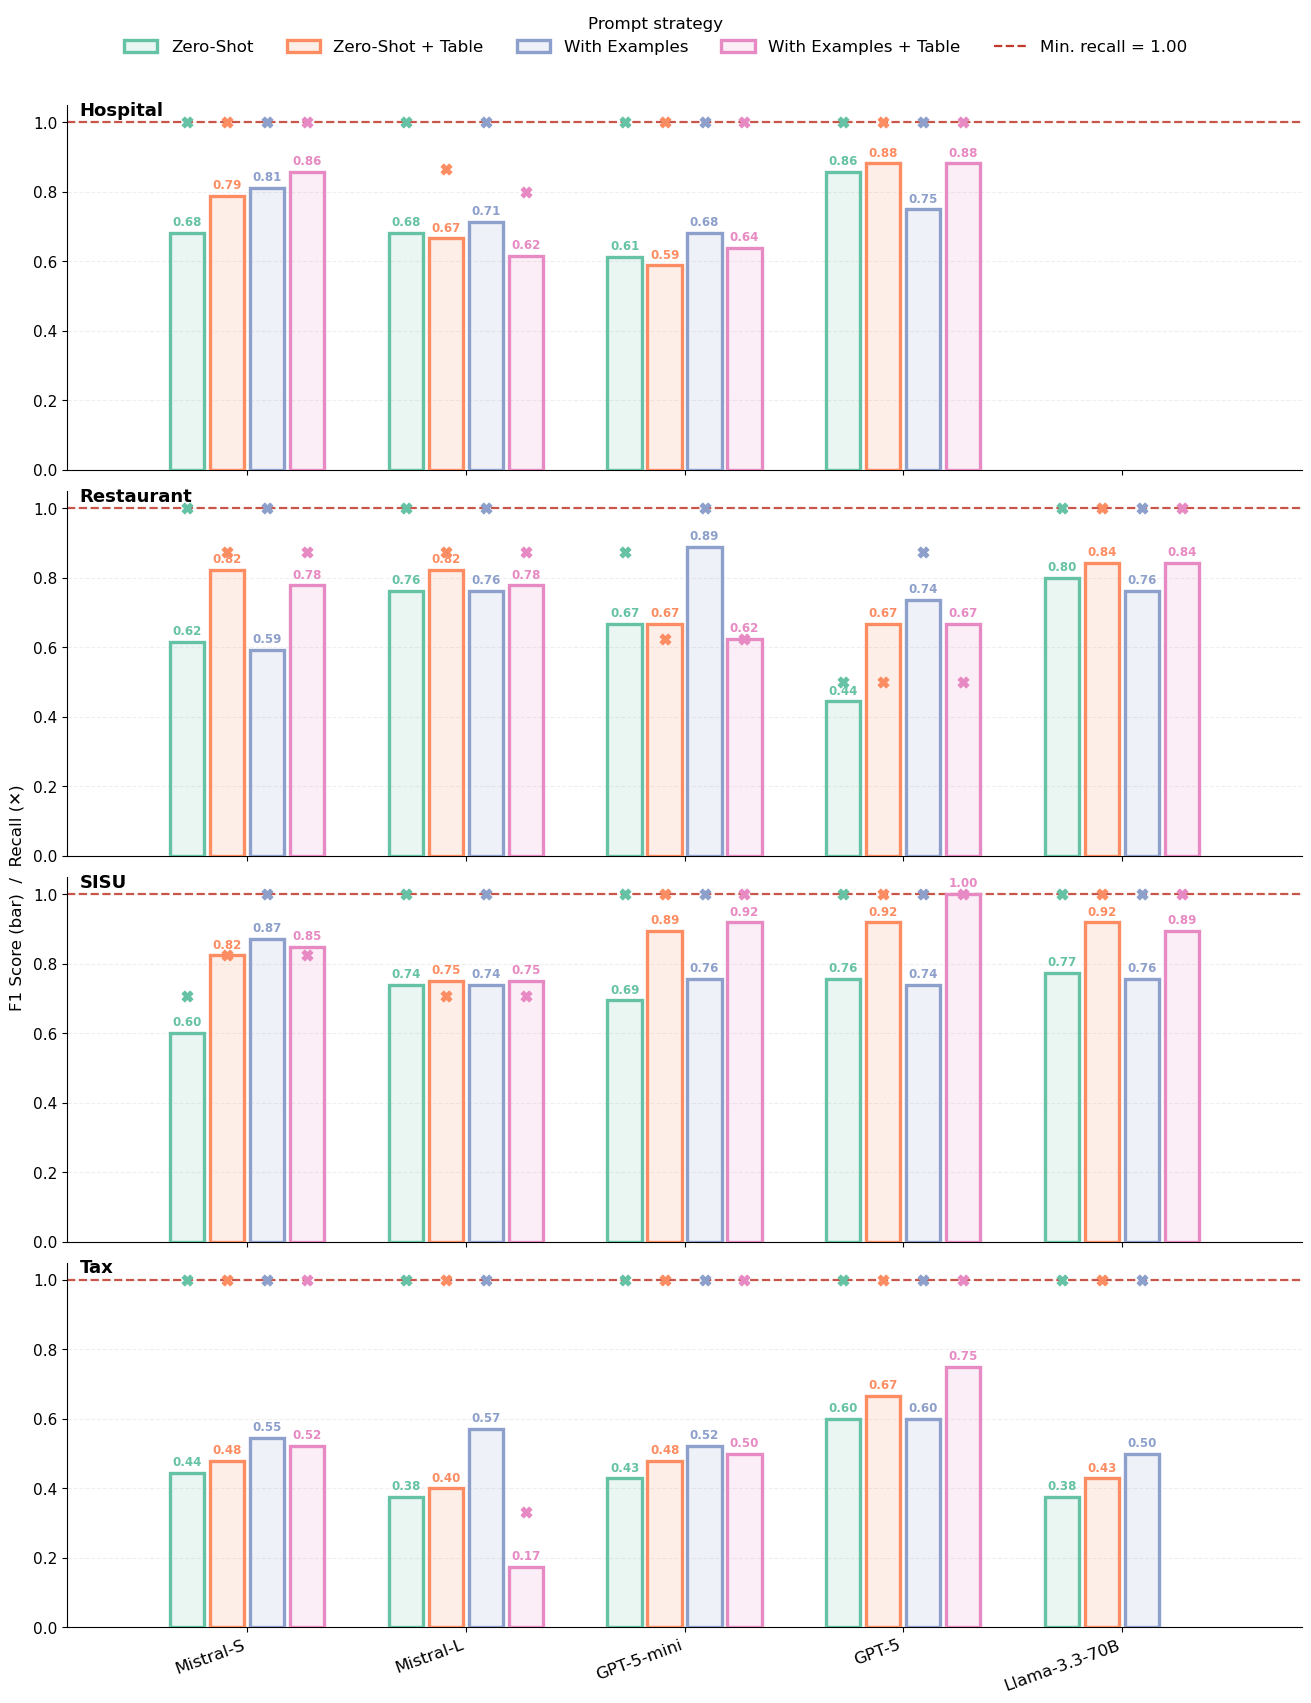

In [20]:
plot_performance_grouped(
    df,
    primary_metric="f1_score",
    secondary_metric="recall",
    min_recall=1.0,
    only_success=True,
    bar_width=0.19,
    group_gap=0.28,
    figsize=(13, 4),
    annotate_values=True,
    save_path="classsifer_performance_overview.pdf",
    dpi=300,
)


In [21]:
def analyse_best_configs(
    df: pd.DataFrame,
    min_recall: float = 0.90,
    only_success: bool = True,
    top_n: int = 5,
) -> None:
    """
    Print a multi-criteria best-configuration analysis:
      1. Per-dataset winner  (highest F1, recall >= min_recall)
      2. Overall ranking     (mean F1 across datasets, recall >= min_recall everywhere)
      3. Most consistent     (lowest std-dev of F1 across datasets)
      4. Highest recall      (mean recall across datasets)
    """
    data = df.copy()
    if only_success and "status" in data.columns:
        data = data[data["status"].astype(str).str.lower().str.contains("success", na=False)]

    for col in ["f1_score", "recall", "precision", "accuracy"]:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors="coerce")

    data = apply_pretty_labels(data)
    data["config"] = data["model_label"] + "  +  " + data["prompt_label"]

    sep = "─" * 72

    # ── 1. Per-dataset winner ─────────────────────────────────────────────────
    print(sep)
    print("  PER-DATASET BEST  (highest F1 with Recall ≥ {:.2f})".format(min_recall))
    print(sep)
    datasets_present = [d for d in DATASET_ORDER if d in data["dataset"].unique()]
    datasets_present += [d for d in data["dataset"].unique() if d not in datasets_present]

    for ds in datasets_present:
        sub = data[(data["dataset"] == ds) & (data["recall"] >= min_recall)]
        label = DATASET_LABELS.get(ds, ds)
        if sub.empty:
            print(f"  {label:<14}  — no config meets recall ≥ {min_recall:.2f}")
        else:
            best = sub.loc[sub["f1_score"].idxmax()]
            print(
                f"  {label:<14}  {best['config']:<35}"
                f"  F1={best['f1_score']:.3f}  Recall={best['recall']:.3f}"
            )

    # ── 2. Overall ranking — mean F1 (recall filter applied per dataset) ──────
    print()
    print(sep)
    print(f"  OVERALL RANKING  (mean F1 across datasets, Recall ≥ {min_recall:.2f} in every dataset)")
    print(sep)

    n_datasets = data["dataset"].nunique()

    agg = (
        data[data["recall"] >= min_recall]
        .groupby("config")
        .agg(
            datasets_passing=("dataset", "nunique"),
            mean_f1=("f1_score", "mean"),
            min_f1=("f1_score", "min"),
            mean_recall=("recall", "mean"),
        )
        .reset_index()
    )
    # Only configs that pass the recall filter in ALL datasets
    agg_all = agg[agg["datasets_passing"] == n_datasets].sort_values("mean_f1", ascending=False)

    if agg_all.empty:
        print("  No single config passes the recall threshold across all datasets.")
    else:
        for rank, (_, row) in enumerate(agg_all.head(top_n).iterrows(), 1):
            print(
                f"  #{rank}  {row['config']:<35}"
                f"  mean F1={row['mean_f1']:.3f}"
                f"  min F1={row['min_f1']:.3f}"
                f"  mean Recall={row['mean_recall']:.3f}"
            )

    # ── 3. Most consistent — lowest std-dev of F1 (all datasets, no recall filter) ──
    print()
    print(sep)
    print("  MOST CONSISTENT  (lowest F1 std-dev across datasets, no recall filter)")
    print(sep)

    std_agg = (
        data.groupby("config")
        .agg(
            datasets=("dataset", "nunique"),
            mean_f1=("f1_score", "mean"),
            std_f1=("f1_score", "std"),
        )
        .reset_index()
    )
    std_agg = std_agg[std_agg["datasets"] == n_datasets].sort_values(
        ["std_f1", "mean_f1"], ascending=[True, False]
    )
    for rank, (_, row) in enumerate(std_agg.head(top_n).iterrows(), 1):
        print(
            f"  #{rank}  {row['config']:<35}"
            f"  mean F1={row['mean_f1']:.3f}"
            f"  std={row['std_f1']:.3f}"
        )

    # ── 4. Highest recall ─────────────────────────────────────────────────────
    print()
    print(sep)
    print("  HIGHEST RECALL  (mean recall across all datasets, top configs)")
    print(sep)

    rec_agg = (
        data.groupby("config")
        .agg(
            datasets=("dataset", "nunique"),
            mean_recall=("recall", "mean"),
            min_recall_val=("recall", "min"),
            mean_f1=("f1_score", "mean"),
        )
        .reset_index()
    )
    rec_agg = rec_agg[rec_agg["datasets"] == n_datasets].sort_values(
        ["mean_recall", "mean_f1"], ascending=[False, False]
    )
    for rank, (_, row) in enumerate(rec_agg.head(top_n).iterrows(), 1):
        print(
            f"  #{rank}  {row['config']:<35}"
            f"  mean Recall={row['mean_recall']:.3f}"
            f"  min Recall={row['min_recall_val']:.3f}"
            f"  mean F1={row['mean_f1']:.3f}"
        )

    print(sep)


analyse_best_configs(df, min_recall=0.90, top_n=5)


────────────────────────────────────────────────────────────────────────
  PER-DATASET BEST  (highest F1 with Recall ≥ 0.90)
────────────────────────────────────────────────────────────────────────
  Hospital        GPT-5  +  Zero-Shot + Table          F1=0.882  Recall=1.000
  Restaurant      GPT-5-mini  +  With Examples         F1=0.889  Recall=1.000
  SISU            GPT-5  +  With Examples + Table      F1=1.000  Recall=1.000
  Tax             GPT-5  +  With Examples + Table      F1=0.750  Recall=1.000

────────────────────────────────────────────────────────────────────────
  OVERALL RANKING  (mean F1 across datasets, Recall ≥ 0.90 in every dataset)
────────────────────────────────────────────────────────────────────────
  #1  GPT-5-mini  +  With Examples         mean F1=0.712  min F1=0.522  mean Recall=1.000
  #2  Mistral-S  +  With Examples          mean F1=0.705  min F1=0.545  mean Recall=1.000
  #3  Mistral-L  +  With Examples          mean F1=0.697  min F1=0.571  mean Recall=1.